# Previsão de atraso na entrega: Olist
## Etapa 2: análise exploratória e pré-processamento

**Disciplina:** Análise Preditiva
**Integrantes:** Guilherme Theis e Paulo Henrique

**Problema:** prever, **no momento da compra**, se um pedido será entregue com atraso.

**Alvo:** `atrasou = 1` se `order_delivered_customer_date > order_estimated_delivery_date`; caso contrário, `0` (classificação binária).

**Dados:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): 9 tabelas, cerca de 100 mil pedidos entre 2016 e 2018.

**Roteiro do notebook**
1. Carga e junção dos dados
2. Análise exploratória
3. Engenharia de features (só informação disponível na compra)
4. Tratamento dos dados
5. Separação treino/teste e validação
6. Decisões e riscos

As funções de junção, criação do alvo e cálculo de distância ficam em `src/features.py`, para serem reaproveitadas na etapa de modelagem.

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Raiz do projeto (o notebook roda de dentro de notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import (COLUNAS_PROIBIDAS, AgrupadorCategoriasRaras, Winsorizador,
                          agregar_geolocalizacao, carregar_tabelas, criar_features_compra,
                          filtrar_entregues, montar_base_pedidos)

RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

SEED = 42
COR_NO_PRAZO, COR_ATRASO = "#4C72B0", "#C44E52"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
set_config(display="diagram")
warnings.filterwarnings("ignore", category=FutureWarning)


def salvar_fig(nome):
    # Salva a figura atual em reports/figures/ e a exibe no notebook.
    plt.tight_layout()
    plt.savefig(FIGURES / f"{nome}.png", dpi=120, bbox_inches="tight")
    plt.show()

---
# 1. Carga e junção dos dados

O dataset vem em um esquema relacional. Para o nosso problema usamos:

| Tabela | Granularidade | Uso |
|---|---|---|
| `orders` | 1 linha por pedido | datas da compra, estimada e real (alvo) |
| `order_items` | **1 linha por item do pedido** | preço, frete, produto, vendedor |
| `customers` | 1 linha por `customer_id` | CEP e estado do cliente |
| `sellers` | 1 linha por vendedor | CEP e estado do vendedor |
| `products` | 1 linha por produto | categoria, peso e dimensões |
| `product_category_name_translation` | 1 linha por categoria | nome da categoria em inglês |
| `geolocation` | **várias linhas por prefixo de CEP** | latitude/longitude |
| `order_reviews` | ~1 linha por pedido | **somente na EDA** (impacto do atraso na nota) |

Os CEPs são lidos como texto para preservar zeros à esquerda (ex.: `01037`).

In [2]:
tabelas = carregar_tabelas(RAW)

pd.DataFrame(
    {nome: {"linhas": df.shape[0], "colunas": df.shape[1]} for nome, df in tabelas.items()}
).T

,linhas,colunas
orders,99441,8
order_items,112650,7
customers,99441,5
sellers,3095,4
products,32951,9
translation,71,2
geolocation,1000163,5
reviews,99224,7
payments,103886,5


### 1.1 Granularidade de `order_items`

Um pedido pode ter vários itens, e cada linha de `order_items` é uma unidade vendida. Se juntássemos essa tabela diretamente com `orders`, cada pedido apareceria repetido e o modelo contaria o mesmo pedido várias vezes. Por isso, **agregamos os itens por pedido antes do join**.

In [3]:
itens = tabelas["order_items"]
itens_por_pedido = itens.groupby("order_id").size()

print(f"Linhas em order_items:      {len(itens):,}")
print(f"Pedidos distintos:          {itens['order_id'].nunique():,}")
print(f"Pedidos com mais de 1 item: {(itens_por_pedido > 1).mean():.1%}")
itens_por_pedido.value_counts().sort_index().head(8).rename("n_pedidos").to_frame().rename_axis("itens_no_pedido")

Linhas em order_items:      112,650
Pedidos distintos:          98,666
Pedidos com mais de 1 item: 9.9%


,n_pedidos
itens_no_pedido,
1,88863
2,7516
3,1322
4,505
5,204
6,198
7,22
8,8


### 1.2 Filtro de pedidos entregues

O alvo só existe para pedidos que **chegaram ao cliente**. Mantemos `order_status == "delivered"` **e** data de entrega preenchida. Pedidos cancelados, indisponíveis ou ainda em trânsito ficam fora.

In [4]:
orders = tabelas["orders"]
display(orders["order_status"].value_counts().rename("pedidos").to_frame())

entregues = filtrar_entregues(orders)
sem_data = ((orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()).sum()
print(f"Pedidos 'delivered' sem data de entrega (descartados): {sem_data}")
print(f"Pedidos mantidos: {len(entregues):,} de {len(orders):,} ({len(entregues)/len(orders):.1%})")

,pedidos
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


Pedidos 'delivered' sem data de entrega (descartados): 8
Pedidos mantidos: 96,470 de 99,441 (97.0%)


### 1.3 Geolocalização: um ponto por prefixo de CEP

A tabela `geolocation` tem **várias coordenadas para o mesmo prefixo de CEP** (um prefixo cobre vários endereços). Fazer o join direto multiplicaria as linhas, então:

1. removemos coordenadas fora dos limites do Brasil (erros de cadastro, com pontos na Europa ou no oceano);
2. calculamos a **latitude e longitude médias por prefixo**;
3. só então fazemos o join com cliente e vendedor.

A distância vendedor → cliente é calculada pela fórmula de **haversine** (distância em linha reta sobre a esfera terrestre, em km). Ela não é a distância rodoviária, mas funciona como uma boa aproximação da dificuldade logística.

In [5]:
geo = tabelas["geolocation"]
geo_agg = agregar_geolocalizacao(geo)

print(f"Linhas em geolocation:          {len(geo):,}")
print(f"Prefixos de CEP distintos:      {geo['geolocation_zip_code_prefix'].nunique():,}")
print(f"Prefixos após limpeza/agregação: {len(geo_agg):,}  (1 linha por prefixo)")
print(f"Prefixo duplicado após agregar? {geo_agg['zip_prefix'].duplicated().any()}")

Linhas em geolocation:          1,000,163
Prefixos de CEP distintos:      19,015
Prefixos após limpeza/agregação: 19,010  (1 linha por prefixo)
Prefixo duplicado após agregar? False


### 1.4 Montagem da base: uma linha por pedido

`montar_base_pedidos` (em `src/features.py`) faz:

1. filtro de entregues + criação do alvo `atrasou`;
2. agregação de `order_items` por pedido, com **soma** de preço, frete, peso e volume e **contagem** de itens, produtos distintos e vendedores distintos;
3. joins com `customers`, `sellers` e a geolocalização agregada (cliente e vendedor);
4. cálculo de `distancia_km`.

**Pedidos com mais de um vendedor:** usamos o **vendedor do item de maior preço** (o "vendedor principal"). Justificativa:
- é o vendedor que responde pela maior parte do valor do pedido;
- é determinístico (empate é resolvido pelo `order_item_id`);
- a alternativa de tirar a média das coordenadas dos vendedores criaria um ponto geográfico fictício, onde não existe vendedor nenhum;
- esses pedidos são raros (ver abaixo), e a informação de que há mais de um vendedor é preservada na feature `n_vendedores`.

O mesmo critério de "item principal" define a **categoria principal** do pedido.

In [6]:
base = montar_base_pedidos(tabelas)

print(f"Pedidos entregues:                     {len(entregues):,}")
print(f"Linhas na base final:                  {len(base):,}")
print(f"Pedidos entregues sem nenhum item:     {len(entregues) - len(base):,} (removidos)")
print(f"order_id duplicados após os joins:     {base['order_id'].duplicated().sum()}")
print(f"Pedidos com mais de um vendedor:       {(base['n_vendedores'] > 1).mean():.2%}")
print(f"Pedidos sem distância (CEP sem coord.): {base['distancia_km'].isna().sum():,} ({base['distancia_km'].isna().mean():.2%})")

assert base["order_id"].is_unique, "A base deveria ter exatamente uma linha por pedido!"

Pedidos entregues:                     96,470
Linhas na base final:                  96,470
Pedidos entregues sem nenhum item:     0 (removidos)
order_id duplicados após os joins:     0
Pedidos com mais de um vendedor:       1.32%
Pedidos sem distância (CEP sem coord.): 477 (0.49%)


In [7]:
base.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,atrasou,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,valor_total,frete_total,n_itens,n_produtos,n_vendedores,peso_total_g,volume_total_cm3,seller_id_principal,categoria_principal,seller_zip_code_prefix,seller_city,seller_state,lat_cliente,lng_cliente,lat_vendedor,lng_vendedor,distancia_km
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,0,7c396fd4830fd04220f754e42b4e5bff,03149,sao paulo,SP,29.99,8.72,1,1,1,500.00,"1,976.00",3504c0cb71d7fa48d967e0e4c94d59d9,utilidades_domesticas,09350,maua,SP,-23.58,-46.59,-23.68,-46.44,18.58
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,0,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,118.70,22.76,1,1,1,400.00,"4,693.00",289cdb325fb7e7f891c38608bf9e0962,perfumaria,31570,belo horizonte,SP,-12.18,-44.66,-19.81,-43.98,851.50
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,0,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,159.90,19.22,1,1,1,420.00,"9,576.00",4869f7a5dfa277a7dca6462dcf3b52b2,automotivo,14840,guariba,SP,-16.75,-48.51,-21.36,-48.23,514.41


---
# 2. Análise exploratória

### 2.1 Tamanho, tipos e valores ausentes

In [8]:
print(f"Base final: {base.shape[0]:,} pedidos x {base.shape[1]} colunas")
print(f"Período das compras: {base['order_purchase_timestamp'].min():%d/%m/%Y} a {base['order_purchase_timestamp'].max():%d/%m/%Y}")

tipos = base.dtypes.astype(str).rename("tipo").to_frame()
tipos["exemplo"] = base.iloc[0].astype(str).str.slice(0, 32)
tipos

Base final: 96,470 pedidos x 30 colunas
Período das compras: 15/09/2016 a 29/08/2018


,tipo,exemplo
order_id,str,e481f51cbdc54678b7cc49136f2d6af7
customer_id,str,9ef432eb6251297304e76186b10a928d
order_status,str,delivered
order_purchase_timestamp,datetime64[us],2017-10-02 10:56:33
order_approved_at,datetime64[us],2017-10-02 11:07:15
order_delivered_carrier_date,datetime64[us],2017-10-04 19:55:00
order_delivered_customer_date,datetime64[us],2017-10-10 21:25:13
order_estimated_delivery_date,datetime64[us],2017-10-18 00:00:00
atrasou,int64,0
customer_unique_id,str,7c396fd4830fd04220f754e42b4e5bff


In [9]:
ausentes = pd.DataFrame({
    "ausentes": base.isna().sum(),
    "pct": base.isna().mean() * 100,
}).query("ausentes > 0").sort_values("ausentes", ascending=False)
ausentes.style.format({"ausentes": "{:,}", "pct": "{:.2f}%"})

,ausentes,pct
categoria_principal,"1,358",1.41%
distancia_km,477,0.49%
lng_cliente,265,0.27%
lat_cliente,265,0.27%
lat_vendedor,213,0.22%
lng_vendedor,213,0.22%
peso_total_g,16,0.02%
volume_total_cm3,16,0.02%
order_approved_at,14,0.01%
order_delivered_carrier_date,1,0.00%


**Leitura:**
- `order_approved_at` e `order_delivered_carrier_date` têm poucos ausentes, mas **não importam**: são informações posteriores à compra e não entram no modelo (seção 3).
- `categoria_principal` (cerca de 1,4%) vem de produtos cadastrados sem categoria, e vai virar a categoria `"desconhecido"`.
- `peso_total_g` e `volume_total_cm3` (16 pedidos) vêm de produtos sem peso ou dimensões e serão imputados pela mediana.
- Coordenadas e `distancia_km` (cerca de 0,5%) faltam quando o prefixo de CEP não existe na tabela de geolocalização, e serão imputados pela mediana.

### 2.2 Distribuição do alvo

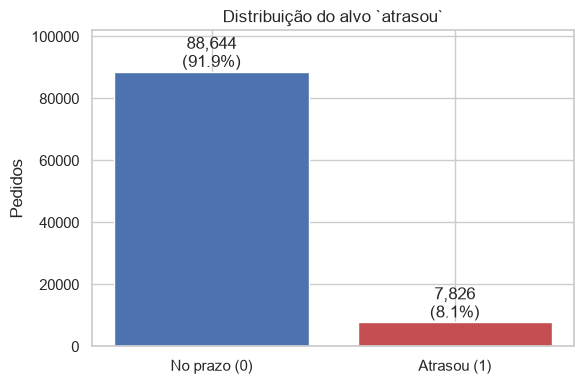

Taxa de atraso: 8.11%
Desbalanceamento: 1 pedido atrasado para cada 11.3 no prazo


In [10]:
contagem = base["atrasou"].value_counts().sort_index()
taxa_atraso = base["atrasou"].mean()

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(["No prazo (0)", "Atrasou (1)"], contagem.values, color=[COR_NO_PRAZO, COR_ATRASO])
for b, v in zip(barras, contagem.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v/contagem.sum():.1%})", ha="center", va="bottom")
ax.set_ylabel("Pedidos")
ax.set_title("Distribuição do alvo `atrasou`")
ax.set_ylim(0, contagem.max() * 1.15)
salvar_fig("01_distribuicao_alvo")

print(f"Taxa de atraso: {taxa_atraso:.2%}")
print(f"Desbalanceamento: 1 pedido atrasado para cada {contagem[0]/contagem[1]:.1f} no prazo")

O problema é **desbalanceado**: só cerca de 8% dos pedidos atrasam. Um modelo que previsse "nunca atrasa" teria cerca de 92% de acurácia sem acertar um único atraso. Por isso, nas próximas etapas, vamos olhar ROC-AUC, PR-AUC, recall e precisão da classe positiva, e não a acurácia.

### 2.3 Taxa de atraso por estado do cliente

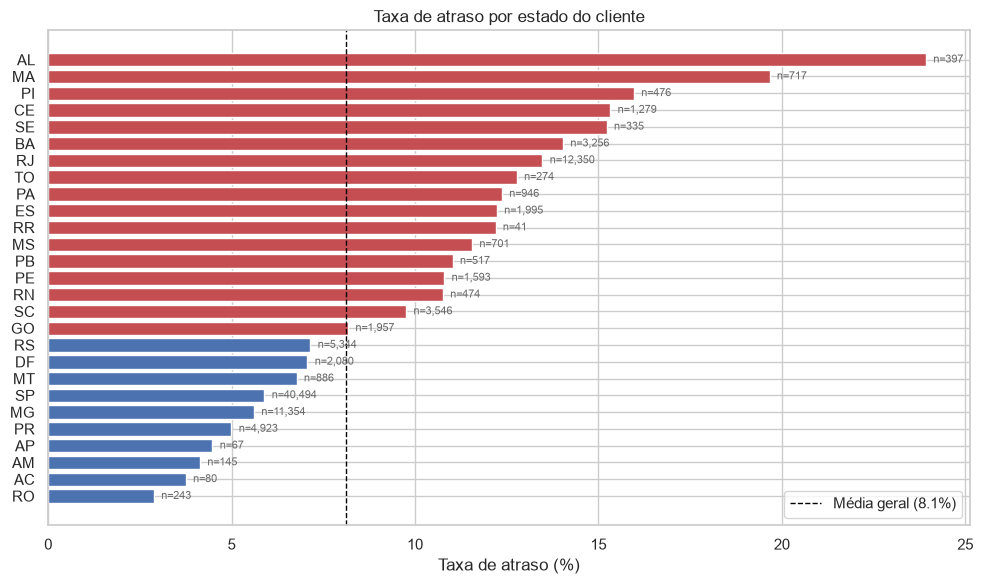

In [11]:
por_uf = (base.groupby("customer_state")["atrasou"]
              .agg(taxa="mean", pedidos="size")
              .sort_values("taxa", ascending=False))

fig, ax = plt.subplots(figsize=(10, 6))
cores = [COR_ATRASO if t > taxa_atraso else COR_NO_PRAZO for t in por_uf["taxa"]]
ax.barh(por_uf.index[::-1], por_uf["taxa"][::-1] * 100, color=cores[::-1])
ax.axvline(taxa_atraso * 100, color="black", ls="--", lw=1, label=f"Média geral ({taxa_atraso:.1%})")
for i, (uf, linha) in enumerate(por_uf[::-1].iterrows()):
    ax.text(linha["taxa"] * 100 + 0.2, i, f"n={int(linha['pedidos']):,}", va="center", fontsize=8, color="dimgray")
ax.set_xlabel("Taxa de atraso (%)")
ax.set_title("Taxa de atraso por estado do cliente")
ax.legend(loc="lower right")
salvar_fig("02_atraso_por_estado")

**Leitura:** os estados do **Norte e Nordeste** (AL, MA, PI, CE, SE, BA...) têm taxas de atraso bem acima da média, enquanto **SP**, que concentra a maior parte dos pedidos e dos vendedores, fica abaixo. Isso indica que **localização e distância** devem ser boas features. Note também o volume (`n`): estados como RR e AP têm poucos pedidos, então suas taxas são instáveis.

### 2.4 Taxa de atraso por categoria de produto

Mostramos as 20 categorias com mais pedidos (as demais têm volume pequeno demais para uma taxa confiável).

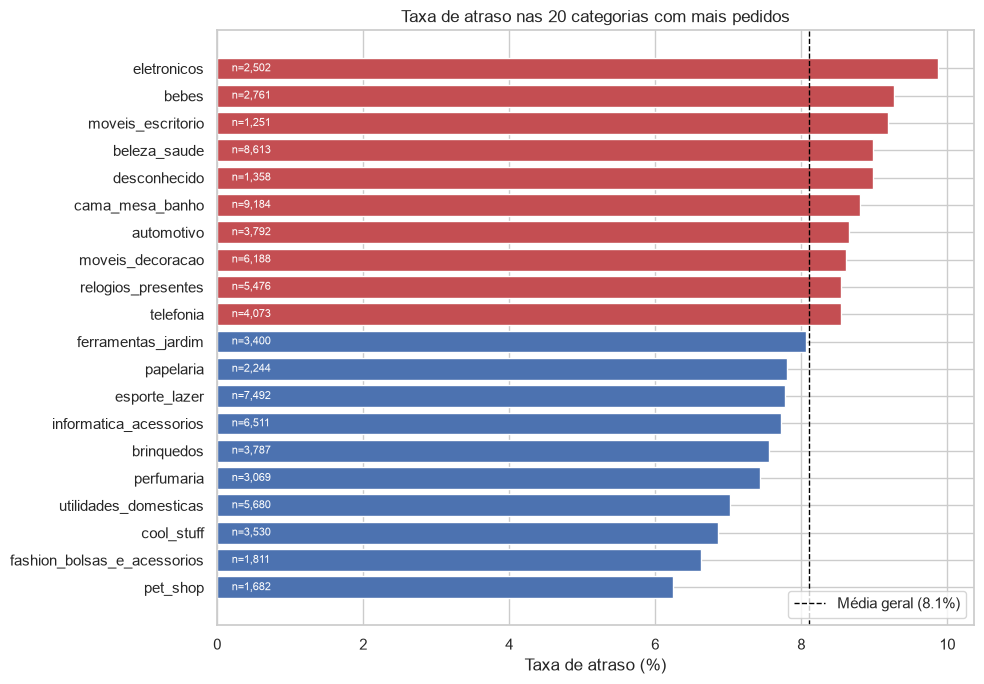

Categorias distintas: 73


In [12]:
por_cat = (base.assign(categoria=base["categoria_principal"].fillna("desconhecido"))
               .groupby("categoria")["atrasou"].agg(taxa="mean", pedidos="size")
               .nlargest(20, "pedidos")
               .sort_values("taxa"))

fig, ax = plt.subplots(figsize=(10, 7))
cores = [COR_ATRASO if t > taxa_atraso else COR_NO_PRAZO for t in por_cat["taxa"]]
ax.barh(por_cat.index, por_cat["taxa"] * 100, color=cores)
ax.axvline(taxa_atraso * 100, color="black", ls="--", lw=1, label=f"Média geral ({taxa_atraso:.1%})")
for i, n in enumerate(por_cat["pedidos"]):
    ax.text(0.2, i, f"n={n:,}", va="center", fontsize=8, color="white")
ax.set_xlabel("Taxa de atraso (%)")
ax.set_title("Taxa de atraso nas 20 categorias com mais pedidos")
ax.legend(loc="lower right")
salvar_fig("03_atraso_por_categoria")

print(f"Categorias distintas: {base['categoria_principal'].nunique()}")

**Leitura:** a variação entre categorias existe, mas é menor que a variação entre estados. Como há 73 categorias, muitas com poucos pedidos, vamos **agrupar as raras em "outros"** no pré-processamento (seção 4).

### 2.5 Taxa de atraso por mês da compra

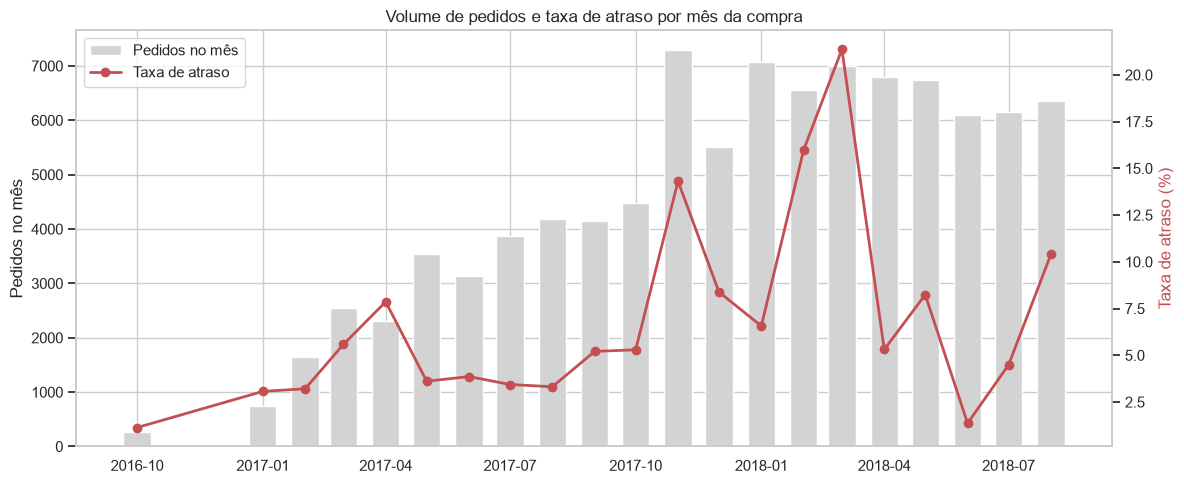

order_purchase_timestamp,2016-10-01,2017-01-01,2017-02-01,2017-03-01,2017-04-01,2017-05-01,2017-06-01,2017-07-01,2017-08-01,2017-09-01,2017-10-01,2017-11-01,2017-12-01,2018-01-01,2018-02-01,2018-03-01,2018-04-01,2018-05-01,2018-06-01,2018-07-01,2018-08-01
taxa,1.10,3.10,3.20,5.60,7.90,3.60,3.90,3.40,3.30,5.20,5.30,14.30,8.40,6.60,16.00,21.40,5.30,8.20,1.40,4.50,10.40
pedidos,265.00,750.00,"1,653.00","2,546.00","2,303.00","3,545.00","3,135.00","3,872.00","4,193.00","4,150.00","4,478.00","7,288.00","5,513.00","7,069.00","6,555.00","7,003.00","6,798.00","6,749.00","6,096.00","6,156.00","6,351.00"


In [13]:
mensal = (base.set_index("order_purchase_timestamp")
              .resample("MS")["atrasou"].agg(taxa="mean", pedidos="size"))
mensal = mensal[mensal["pedidos"] >= 100]  # remove meses quase vazios de 2016

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(mensal.index, mensal["pedidos"], width=20, color="lightgray", label="Pedidos no mês")
ax1.set_ylabel("Pedidos no mês")
ax2 = ax1.twinx()
ax2.plot(mensal.index, mensal["taxa"] * 100, color=COR_ATRASO, marker="o", lw=2, label="Taxa de atraso")
ax2.set_ylabel("Taxa de atraso (%)", color=COR_ATRASO)
ax2.grid(False)
ax1.set_title("Volume de pedidos e taxa de atraso por mês da compra")
linhas = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(linhas, ["Pedidos no mês", "Taxa de atraso"], loc="upper left")
salvar_fig("04_atraso_por_mes")

mensal.assign(taxa=lambda d: (d["taxa"] * 100).round(1)).T

**Leitura:** a taxa de atraso **não é estável no tempo**. Há picos em **nov/2017** (Black Friday) e em **fev-mar/2018**, quando passou de 15-20%, e períodos com taxas baixíssimas, como jun/2018. Isso tem duas consequências:
1. o mês da compra carrega sinal (sazonalidade, picos de demanda);
2. a **divisão temporal** do treino/teste (seção 5) vai mostrar taxas diferentes entre treino e teste, o que é um teste realista de robustez do modelo.

### 2.6 Distribuições numéricas e outliers

Frete, preço, peso e distância têm distribuição muito **assimétrica** (cauda longa à direita), então os histogramas usam escala logarítmica no eixo x. Os boxplots separam pedidos no prazo e atrasados.

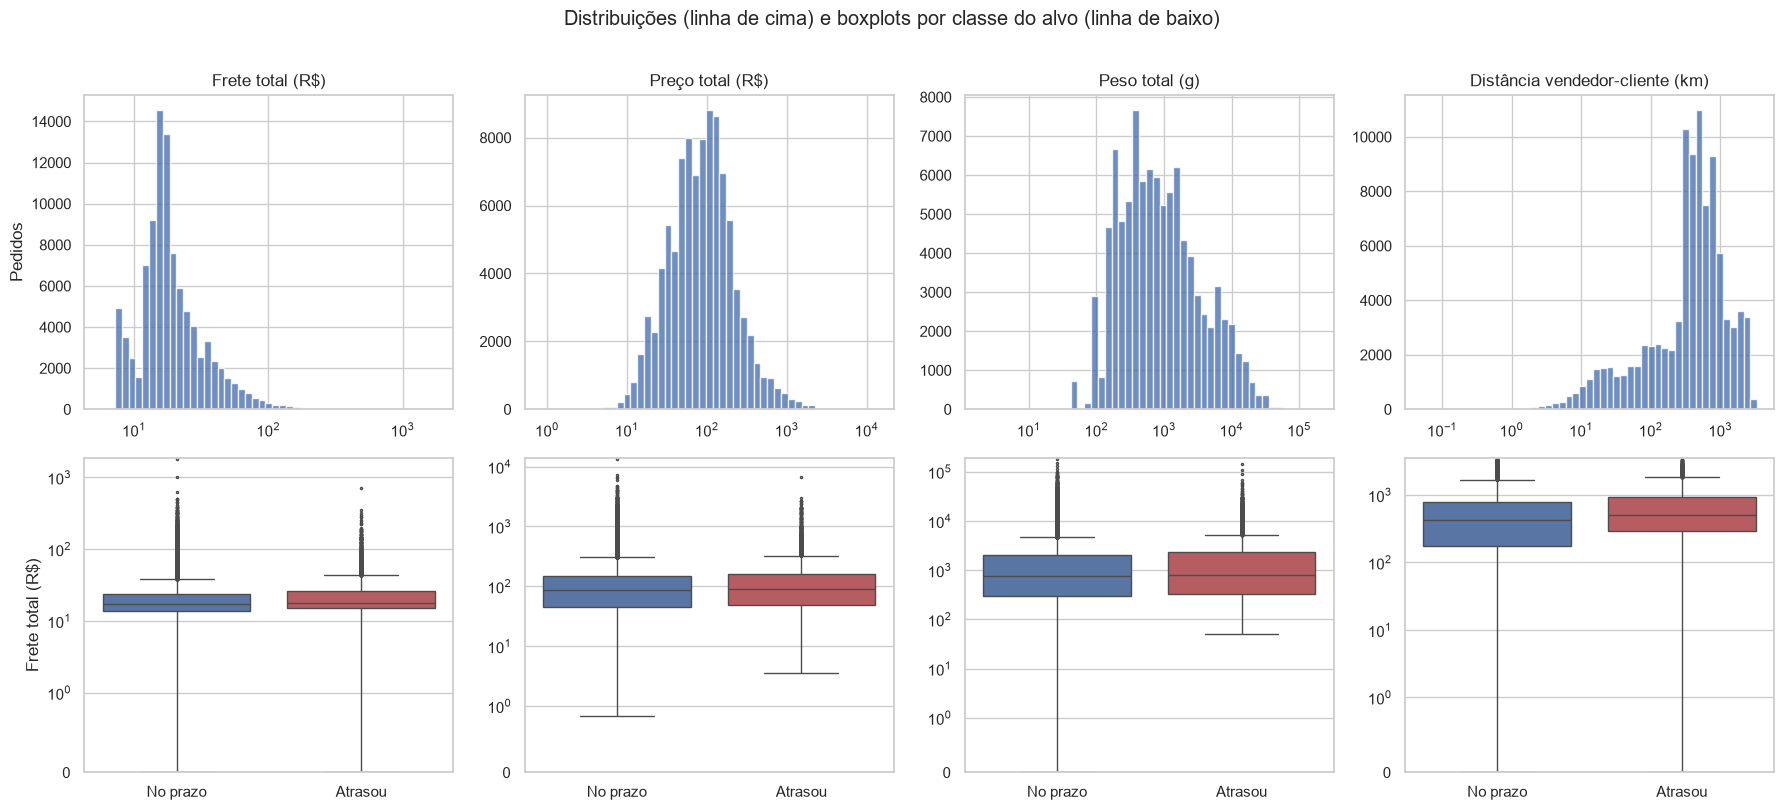

In [14]:
variaveis = {
    "frete_total": "Frete total (R$)",
    "valor_total": "Preço total (R$)",
    "peso_total_g": "Peso total (g)",
    "distancia_km": "Distância vendedor-cliente (km)",
}

fig, eixos = plt.subplots(2, 4, figsize=(18, 8))
for j, (col, rotulo) in enumerate(variaveis.items()):
    dados = base[col].dropna()
    positivos = dados[dados > 0]
    bins = np.logspace(np.log10(positivos.min()), np.log10(positivos.max()), 50)
    eixos[0, j].hist(positivos, bins=bins, color=COR_NO_PRAZO, alpha=0.8)
    eixos[0, j].set_xscale("log")
    eixos[0, j].set_title(rotulo)
    eixos[0, j].set_ylabel("Pedidos" if j == 0 else "")

    sns.boxplot(data=base, x="atrasou", y=col, ax=eixos[1, j], hue="atrasou",
                palette=[COR_NO_PRAZO, COR_ATRASO], legend=False, fliersize=1.5)
    eixos[1, j].set_yscale("symlog", linthresh=1)
    eixos[1, j].set_ylim(bottom=0)
    eixos[1, j].set_xticks([0, 1], ["No prazo", "Atrasou"])
    eixos[1, j].set_xlabel("")
    eixos[1, j].set_ylabel(rotulo if j == 0 else "")
fig.suptitle("Distribuições (linha de cima) e boxplots por classe do alvo (linha de baixo)", y=1.01)
salvar_fig("05_distribuicoes_outliers")

In [15]:
def resumo_outliers(df, col):
    s = df[col].dropna()
    p1, p99 = s.quantile([0.01, 0.99])
    q1, q3 = s.quantile([0.25, 0.75])
    lim_iqr = q3 + 1.5 * (q3 - q1)
    acima_p99 = df[col] > p99
    return {
        "mín": s.min(), "p1": p1, "mediana": s.median(), "p99": p99, "máx": s.max(),
        "% acima IQR": (s > lim_iqr).mean() * 100,
        "atraso acima p99 (%)": df.loc[acima_p99, "atrasou"].mean() * 100,
        "atraso até p99 (%)": df.loc[~acima_p99 & df[col].notna(), "atrasou"].mean() * 100,
    }

pd.DataFrame({c: resumo_outliers(base, c) for c in variaveis}).T

,mín,p1,mediana,p99,máx,% acima IQR,atraso acima p99 (%),atraso até p99 (%)
frete_total,0.00,7.39,17.17,104.25,"1,794.96",10.05,11.19,8.08
valor_total,0.85,11.99,86.50,990.00,"13,440.00",7.94,9.44,8.10
peso_total_g,0.00,100.00,750.00,"22,350.00","184,400.00",14.04,10.50,8.09
distancia_km,0.00,5.72,433.81,"2,482.95","3,399.19",7.74,11.67,8.06


**Leitura:**
- Todas as variáveis têm muitos pontos acima do limite de Tukey (Q3 + 1,5·IQR), o que é **esperado em cauda longa** e não indica erro de digitação: um pedido de R$ 6.000 ou um frete de R$ 400 existem de verdade (móveis, eletrodomésticos, entregas para o Norte).
- A última coluna compara a taxa de atraso dos pedidos acima do p99 com a dos demais. Frete e distância extremos **atrasam mais**, ou seja, **os outliers carregam sinal real** e não devem ser removidos.
- A decisão de tratamento (winsorização em vez de remoção) está na seção 4.

### 2.7 Impacto do atraso na satisfação (`review_score`)

Juntamos `order_reviews` **somente aqui**, para mostrar por que o problema importa. A nota é dada **depois** da entrega, então ela **não pode ser feature** do modelo.

A tabela de reviews tem alguns pedidos com mais de uma avaliação. Mantemos **a resposta mais recente** de cada pedido (`review_answer_timestamp`), para ficar com uma nota por pedido.

In [16]:
reviews = tabelas["reviews"]
print(f"Reviews: {len(reviews):,} linhas | pedidos distintos: {reviews['order_id'].nunique():,} "
      f"| pedidos com mais de 1 review: {reviews['order_id'].duplicated().sum():,}")

reviews_unicos = (reviews.sort_values("review_answer_timestamp")
                         .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]])

eda_reviews = base[["order_id", "atrasou"]].merge(reviews_unicos, on="order_id", how="inner")
assert eda_reviews["order_id"].is_unique
print(f"Pedidos da base com review: {len(eda_reviews):,} ({len(eda_reviews)/len(base):.1%})")

nota = eda_reviews.groupby("atrasou")["review_score"].agg(nota_media="mean", pedidos="size",
                                                         pct_nota_1=lambda s: (s == 1).mean() * 100)
nota.index = ["No prazo", "Atrasou"]
nota

Reviews: 99,224 linhas | pedidos distintos: 98,673 | pedidos com mais de 1 review: 551
Pedidos da base com review: 95,824 (99.3%)


,nota_media,pedidos,pct_nota_1
No prazo,4.29,88163,6.59
Atrasou,2.57,7661,46.21


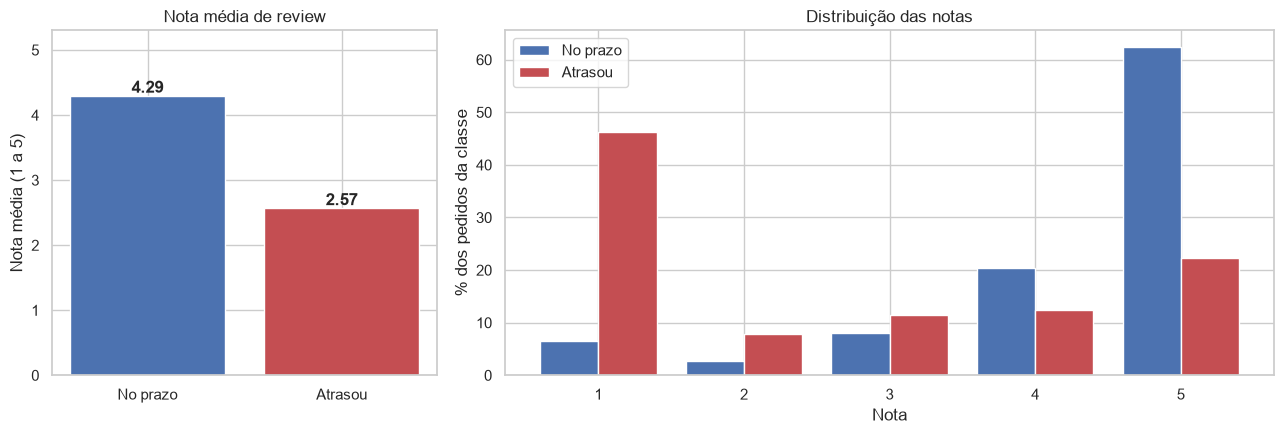

In [17]:
dist_nota = (pd.crosstab(eda_reviews["atrasou"], eda_reviews["review_score"], normalize="index") * 100)
dist_nota.index = ["No prazo", "Atrasou"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2]})
ax1.bar(nota.index, nota["nota_media"], color=[COR_NO_PRAZO, COR_ATRASO])
for i, v in enumerate(nota["nota_media"]):
    ax1.text(i, v + 0.05, f"{v:.2f}", ha="center", fontweight="bold")
ax1.set_ylim(0, 5.3)
ax1.set_ylabel("Nota média (1 a 5)")
ax1.set_title("Nota média de review")

x = np.arange(1, 6)
ax2.bar(x - 0.2, dist_nota.loc["No prazo"], width=0.4, color=COR_NO_PRAZO, label="No prazo")
ax2.bar(x + 0.2, dist_nota.loc["Atrasou"], width=0.4, color=COR_ATRASO, label="Atrasou")
ax2.set_xticks(x)
ax2.set_xlabel("Nota")
ax2.set_ylabel("% dos pedidos da classe")
ax2.set_title("Distribuição das notas")
ax2.legend()
salvar_fig("06_review_vs_atraso")

**Leitura:** o atraso **derruba a satisfação**. A nota média cai de **4,29 para 2,57**, e a nota 1 passa de 6,6% para **46%** dos pedidos atrasados: quase metade dos clientes com atraso dá a nota mínima. Isso justifica o problema de negócio: se o atraso for previsto na compra, a Olist pode agir antes (avisar o cliente, ajustar o prazo prometido, priorizar o envio).

> Ressalva: só vemos a nota de quem **avaliou**. Clientes muito insatisfeitos (ou muito satisfeitos) podem avaliar mais que os demais.

---
# 3. Engenharia de features (só informação disponível NA COMPRA)

A regra de ouro: o modelo vai rodar **no instante em que o cliente fecha o pedido**. Qualquer informação que só existe depois disso causaria **vazamento de dados** (*data leakage*). O modelo pareceria ótimo no teste e seria inútil na prática.

| Feature | Origem | Disponível na compra? |
|---|---|---|
| `prazo_prometido_dias` | data estimada − data da compra | Sim, a data estimada é exibida no checkout |
| `mes_compra`, `dia_semana_compra` | data da compra | Sim |
| `valor_total`, `frete_total`, `razao_frete_preco` | soma dos itens | Sim, é o carrinho |
| `n_itens`, `n_vendedores` | contagem dos itens | Sim |
| `peso_total_g`, `volume_total_cm3` | cadastro do produto x itens | Sim |
| `categoria_principal` | categoria do item de maior preço | Sim |
| `estado_cliente`, `estado_vendedor`, `mesmo_estado` | cadastros | Sim |
| `distancia_km` | haversine entre CEPs | Sim |

**Proibidas:** `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `shipping_limit_date`, `order_status`, todas as colunas `review_*` e qualquer coisa derivada delas (ex.: tempo até aprovação, tempo de postagem).

In [18]:
features = criar_features_compra(base)

COLS_NUMERICAS = ["prazo_prometido_dias", "valor_total", "frete_total", "razao_frete_preco",
                  "n_itens", "n_vendedores", "peso_total_g", "volume_total_cm3", "distancia_km"]
COLS_CATEGORICAS = ["categoria_principal", "estado_cliente", "estado_vendedor"]
COLS_CALENDARIO = ["mes_compra", "dia_semana_compra"]
COLS_BINARIAS = ["mesmo_estado"]
FEATURES = COLS_NUMERICAS + COLS_CATEGORICAS + COLS_CALENDARIO + COLS_BINARIAS
ALVO = "atrasou"

features[FEATURES + [ALVO]].head()

,prazo_prometido_dias,valor_total,frete_total,razao_frete_preco,n_itens,n_vendedores,peso_total_g,volume_total_cm3,distancia_km,categoria_principal,estado_cliente,estado_vendedor,mes_compra,dia_semana_compra,mesmo_estado,atrasou
0,15.54,29.99,8.72,0.29,1,1,500.00,"1,976.00",18.58,utilidades_domesticas,SP,SP,10,0,1,0
1,19.14,118.70,22.76,0.19,1,1,400.00,"4,693.00",851.50,perfumaria,BA,SP,7,1,0,0
2,26.64,159.90,19.22,0.12,1,1,420.00,"9,576.00",514.41,automotivo,GO,SP,8,2,0,0
3,26.19,45.00,27.20,0.60,1,1,450.00,"6,000.00","1,822.23",pet_shop,RN,MG,11,5,0,0
4,12.11,19.90,8.72,0.44,1,1,250.00,"11,475.00",29.68,papelaria,SP,SP,2,1,1,0


### Verificação anti-vazamento

A célula abaixo lista as colunas finais do modelo e **confirma por código** que nenhuma delas é uma coluna proibida. Ela também confere que nenhum nome derivado de uma proibida aparece (aprovação, envio, entrega real, review, status).

In [19]:
print(f"{len(FEATURES)} features usadas no modelo:")
for grupo, cols in [("Numéricas", COLS_NUMERICAS), ("Categóricas", COLS_CATEGORICAS),
                    ("Calendário (da compra)", COLS_CALENDARIO), ("Binárias", COLS_BINARIAS)]:
    print(f"  {grupo:<24} {cols}")

proibidas_usadas = set(FEATURES) & set(COLUNAS_PROIBIDAS)
termos_suspeitos = ["approved", "carrier", "delivered", "review", "status", "shipping", "entrega_real"]
suspeitas = [c for c in FEATURES if any(t in c for t in termos_suspeitos)]

assert not proibidas_usadas, f"Coluna proibida nas features: {proibidas_usadas}"
assert not suspeitas, f"Feature derivada de informação pós-compra: {suspeitas}"
assert ALVO not in FEATURES
print("\nOK: nenhuma coluna proibida ou derivada de informação posterior à compra está nas features.")

15 features usadas no modelo:
  Numéricas                ['prazo_prometido_dias', 'valor_total', 'frete_total', 'razao_frete_preco', 'n_itens', 'n_vendedores', 'peso_total_g', 'volume_total_cm3', 'distancia_km']
  Categóricas              ['categoria_principal', 'estado_cliente', 'estado_vendedor']
  Calendário (da compra)   ['mes_compra', 'dia_semana_compra']
  Binárias                 ['mesmo_estado']

OK: nenhuma coluna proibida ou derivada de informação posterior à compra está nas features.


In [20]:
features[COLS_NUMERICAS].describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
prazo_prometido_dias,"96,470.00",23.74,8.76,2.01,6.05,23.23,50.21,155.14
valor_total,"96,470.00",137.04,209.05,0.85,11.99,86.50,990.00,"13,440.00"
frete_total,"96,470.00",22.79,21.56,0.00,7.39,17.17,104.25,"1,794.96"
razao_frete_preco,"96,470.00",0.31,0.31,0.00,0.03,0.22,1.46,21.45
n_itens,"96,470.00",1.14,0.54,1.00,1.00,1.00,3.00,21.00
n_vendedores,"96,470.00",1.01,0.12,1.00,1.00,1.00,2.00,5.00
peso_total_g,"96,454.00","2,386.87","4,770.11",0.00,100.00,750.00,"22,350.00","184,400.00"
volume_total_cm3,"96,454.00","17,331.94","30,143.87",168.00,352.00,"7,254.00","135,690.82","1,476,000.00"
distancia_km,"95,993.00",600.37,592.25,0.00,5.72,433.81,"2,482.95","3,399.19"


**Uma olhada rápida no sinal das features novas:** taxa de atraso por faixa de prazo prometido e de distância.

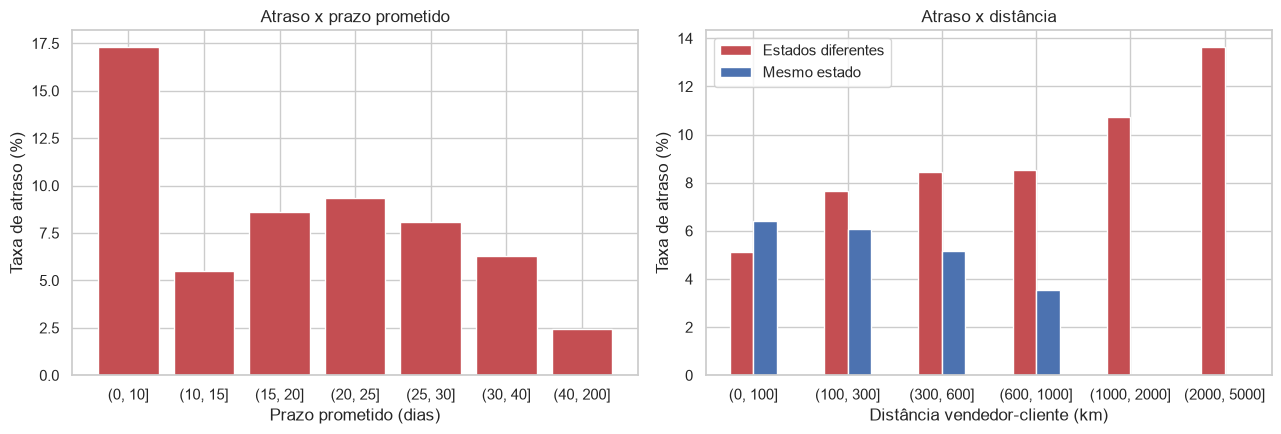

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

faixas_prazo = pd.cut(features["prazo_prometido_dias"], [0, 10, 15, 20, 25, 30, 40, 200])
t1 = features.groupby(faixas_prazo, observed=True)["atrasou"].mean() * 100
ax1.bar(t1.index.astype(str), t1.values, color=COR_ATRASO)
ax1.set_xlabel("Prazo prometido (dias)")
ax1.set_ylabel("Taxa de atraso (%)")
ax1.set_title("Atraso x prazo prometido")

mesmo = features["mesmo_estado"].map({1: "Mesmo estado", 0: "Estados diferentes"})
faixas_dist = pd.cut(features["distancia_km"], [0, 100, 300, 600, 1000, 2000, 5000])
t2 = features.groupby([faixas_dist, mesmo], observed=True)["atrasou"].mean().unstack() * 100
t2.plot(kind="bar", ax=ax2, color=[COR_ATRASO, COR_NO_PRAZO], rot=0)
ax2.set_xlabel("Distância vendedor-cliente (km)")
ax2.set_ylabel("Taxa de atraso (%)")
ax2.set_title("Atraso x distância")
ax2.legend(title="")
salvar_fig("07_atraso_prazo_distancia")

**Leitura:** prazos prometidos **curtos** atrasam mais (a promessa é mais difícil de cumprir) e a taxa de atraso **cresce com a distância**. As duas features devem ter peso relevante no modelo.

---
# 4. Tratamento dos dados

Toda transformação que **aprende algo dos dados** (mediana, percentis, categorias frequentes, média e desvio do scaler) fica dentro de um `Pipeline` do scikit-learn e é ajustada **somente no conjunto de treino** (seção 5). Se calculássemos a mediana ou os percentis na base inteira, informação do teste vazaria para o treino.

### 4.1 Valores ausentes: decisão por coluna

In [22]:
aus = pd.DataFrame({
    "ausentes": features[FEATURES].isna().sum(),
    "pct": features[FEATURES].isna().mean() * 100,
})
decisao = {
    "categoria_principal": "Categoria 'desconhecido': produto sem categoria cadastrada é informação válida",
    "peso_total_g": "Imputar mediana (do treino): 16 pedidos, impacto desprezível",
    "volume_total_cm3": "Imputar mediana (do treino): mesmos 16 pedidos sem dimensões",
    "distancia_km": "Imputar mediana (do treino): CEP sem coordenada; remover descartaria pedidos válidos",
}
aus["decisão"] = aus.index.map(decisao).fillna("—")
aus.sort_values("ausentes", ascending=False).style.format({"ausentes": "{:,}", "pct": "{:.2f}%"})

,ausentes,pct,decisão
categoria_principal,"1,358",1.41%,Categoria 'desconhecido': produto sem categoria cadastrada é informação válida
distancia_km,477,0.49%,Imputar mediana (do treino): CEP sem coordenada; remover descartaria pedidos válidos
peso_total_g,16,0.02%,"Imputar mediana (do treino): 16 pedidos, impacto desprezível"
volume_total_cm3,16,0.02%,Imputar mediana (do treino): mesmos 16 pedidos sem dimensões
frete_total,0,0.00%,—
valor_total,0,0.00%,—
prazo_prometido_dias,0,0.00%,—
n_vendedores,0,0.00%,—
n_itens,0,0.00%,—
razao_frete_preco,0,0.00%,—


**Justificativas:**
- **Não removemos linhas:** o total de ausentes é inferior a 2% e eles não são aleatórios (ex.: CEPs de regiões menos cobertas pela tabela de geolocalização). Remover enviesaria a base.
- **Mediana e não média:** as variáveis são muito assimétricas, e a média seria puxada pela cauda.
- **"desconhecido" para categoria:** ausência de categoria pode refletir vendedores com cadastro mais pobre, ou seja, pode ser um sinal. A categoria explícita preserva isso.
- As colunas de estado (cliente e vendedor) não têm ausentes, mas o mesmo tratamento é aplicado por segurança.

### 4.2 Outliers: mostrar e decidir

Na seção 2.6 vimos que os valores extremos são **reais** (fretes e distâncias altos de fato existem) e que **carregam sinal** (atrasam mais). Opções:

| Opção | Prós | Contras |
|---|---|---|
| Remover | modelo "limpo" | joga fora justamente os pedidos de maior risco |
| Manter como está | não perde informação | pontos extremos dominam a regressão logística e o `StandardScaler` |
| **Winsorizar no p99** | mantém todas as linhas e a ordem dos valores; limita a influência | perde a distinção *entre* valores extremos |

**Decisão:** **winsorizar a cauda superior** das variáveis numéricas no **percentil 99, calculado no treino**. Um frete de R$ 400 continua sendo "frete máximo" para o modelo, mas não distorce a escala das demais observações. Nenhuma linha é removida.

**Por que só a cauda superior:** as variáveis são limitadas em zero, e os valores mínimos são **legítimos e informativos**: frete R$ 0,00 é frete grátis e distância 0 km é vendedor e cliente no mesmo prefixo de CEP. Limitar no p1 transformaria frete grátis em R$ 7,39. Em um teste com a baseline, limitar só o p99 deu ROC-AUC melhor que limitar p1 e p99.

Para modelos de árvore, essa etapa é praticamente neutra, porque árvores dependem só da ordem dos valores.

Exemplo do efeito (percentis calculados na base toda **apenas para ilustrar**; no pipeline eles são aprendidos no treino):

In [23]:
demo = Winsorizador(inferior=0.0, superior=0.99).fit(features[COLS_NUMERICAS])
antes_depois = pd.DataFrame({
    "mín (mantido)": features[COLS_NUMERICAS].min(),
    "mediana": features[COLS_NUMERICAS].median(),
    "máx antes": features[COLS_NUMERICAS].max(),
    "limite p99": demo.limites_sup_,
    "% linhas limitadas": (features[COLS_NUMERICAS] > demo.limites_sup_).mean() * 100,
})
antes_depois

,mín (mantido),mediana,máx antes,limite p99,% linhas limitadas
prazo_prometido_dias,2.01,23.23,155.14,50.21,1.00
valor_total,0.85,86.50,"13,440.00",990.00,1.00
frete_total,0.00,17.17,"1,794.96",104.25,1.00
razao_frete_preco,0.00,0.22,21.45,1.46,1.00
n_itens,1.00,1.00,21.00,3.00,0.97
n_vendedores,1.00,1.00,5.00,2.00,0.06
peso_total_g,0.00,750.00,"184,400.00","22,350.00",0.97
volume_total_cm3,168.00,"7,254.00","1,476,000.00","135,690.82",1.00
distancia_km,0.00,433.81,"3,399.19","2,482.95",1.00


### 4.3 Variáveis categóricas

- **`categoria_principal` (73 categorias, alta cardinalidade):** categorias com menos de **1% dos pedidos do treino** são agrupadas em `"outros"`, e só depois aplicamos one-hot. Isso evita dezenas de colunas quase vazias, que geram coeficientes instáveis. Qualquer categoria nova que apareça no teste também cai em `"outros"`.
- **`estado_cliente` e `estado_vendedor` (27 e 23 valores):** one-hot. Estados com menos de 0,2% dos pedidos de treino vão para `"outros"`, pelo mesmo motivo. No treino temporal, isso afeta AM, AC, AP e RR (cliente) e MT, CE, RN, MS, PB, RO, PI, PA, SE e AM (vendedor).
- **`mes_compra` e `dia_semana_compra`:** apesar de numéricos, são **cíclicos** (dezembro não é "12 vezes" janeiro), então entram como one-hot.
- **`mesmo_estado`:** já é 0/1 e passa direto.

Implementado em `AgrupadorCategoriasRaras` (`src/features.py`), que aprende a lista de categorias frequentes no `fit` (treino).

### 4.4 Escala

Aplicamos `StandardScaler` (média 0, desvio 1) nas numéricas, depois da imputação e da winsorização.

- **Importa para a regressão logística** (e para outros modelos baseados em distância ou gradiente, como SVM, KNN e redes neurais): a regularização penaliza todos os coeficientes igualmente, então variáveis em escalas muito diferentes (R$ versus km versus gramas) seriam penalizadas de forma desigual, e a otimização converge pior.
- **Não importa para árvores** (Decision Tree, Random Forest, Gradient Boosting): elas escolhem pontos de corte (`frete > 30?`), e um corte é o mesmo antes e depois de uma transformação monotônica. Manter o scaler no pipeline não prejudica as árvores.

### 4.5 Pipeline completo

In [24]:
def criar_preprocessador():
    numerico = Pipeline([
        ("imputar_mediana", SimpleImputer(strategy="median")),
        ("winsorizar", Winsorizador(inferior=0.0, superior=0.99)),
        ("escalar", StandardScaler()),
    ])
    categoria = Pipeline([
        ("agrupar_raras", AgrupadorCategoriasRaras(min_freq=0.01)),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    estados = Pipeline([
        ("agrupar_raras", AgrupadorCategoriasRaras(min_freq=0.002)),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    calendario = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    return ColumnTransformer([
        ("num", numerico, COLS_NUMERICAS),
        ("cat_produto", categoria, ["categoria_principal"]),
        ("cat_estados", estados, ["estado_cliente", "estado_vendedor"]),
        ("calendario", calendario, COLS_CALENDARIO),
        ("binarias", "passthrough", COLS_BINARIAS),
    ], verbose_feature_names_out=True)


criar_preprocessador()

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat_produto', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``f

---
# 5. Separação treino/teste e validação

### 5.1 Divisão principal: temporal

Ordenamos os pedidos pela **data da compra**: os **80% mais antigos** formam o treino e os **20% mais recentes**, o teste.

**Por quê:** na vida real, o modelo é treinado com o histórico e usado para prever **pedidos futuros**. Uma divisão aleatória misturaria pedidos de mar/2018 no treino e de fev/2018 no teste, e o modelo "veria o futuro", como o pico de atrasos daquele trimestre. A divisão temporal simula o uso real e dá uma estimativa de desempenho mais honesta, inclusive diante de mudanças de padrão ao longo do tempo.

In [25]:
features = features.sort_values("data_compra").reset_index(drop=True)
corte = int(len(features) * 0.8)
data_corte = features.loc[corte, "data_compra"]

treino_t = features.iloc[:corte]
teste_t = features.iloc[corte:]

X_treino, y_treino = treino_t[FEATURES], treino_t[ALVO]
X_teste, y_teste = teste_t[FEATURES], teste_t[ALVO]

print(f"Data de corte: {data_corte:%d/%m/%Y %H:%M}")

Data de corte: 26/05/2018 18:18


### 5.2 Comparação: divisão estratificada 80/20 (aleatória)

Apenas para comparação. `stratify=y` garante a mesma proporção de atrasos nos dois conjuntos.

In [26]:
X_tr_e, X_te_e, y_tr_e, y_te_e = train_test_split(
    features[FEATURES], features[ALVO], test_size=0.2, stratify=features[ALVO], random_state=SEED)

def descrever(nome, df_datas, y):
    return {"divisão": nome.split(" | ")[0], "conjunto": nome.split(" | ")[1], "pedidos": len(y),
            "início": df_datas.min().strftime("%d/%m/%Y"), "fim": df_datas.max().strftime("%d/%m/%Y"),
            "taxa de atraso (%)": y.mean() * 100}

comparacao = pd.DataFrame([
    descrever("Temporal | treino", treino_t["data_compra"], y_treino),
    descrever("Temporal | teste", teste_t["data_compra"], y_teste),
    descrever("Estratificada | treino", features.loc[X_tr_e.index, "data_compra"], y_tr_e),
    descrever("Estratificada | teste", features.loc[X_te_e.index, "data_compra"], y_te_e),
]).set_index(["divisão", "conjunto"])
comparacao.style.format({"pedidos": "{:,}", "taxa de atraso (%)": "{:.2f}"})

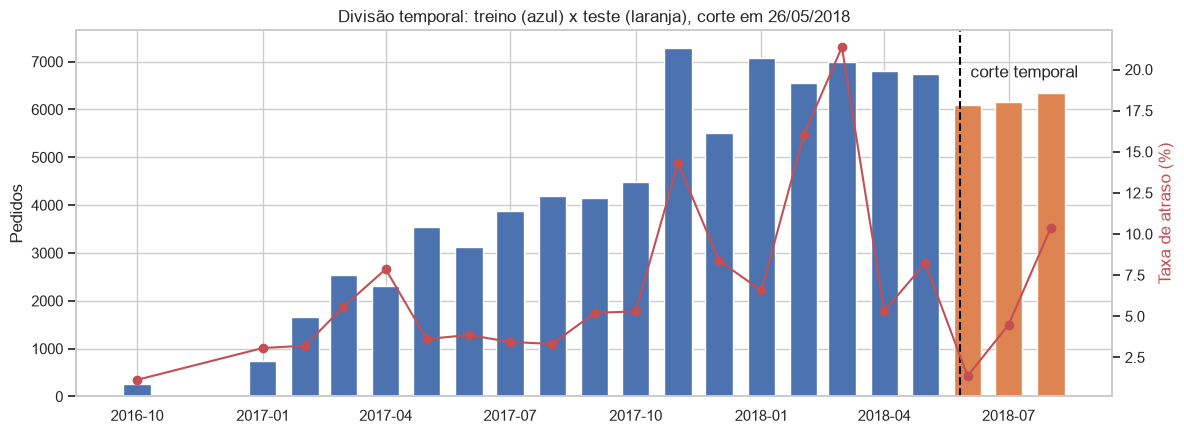

In [27]:
mensal_split = features.set_index("data_compra").resample("MS")[ALVO].agg(["size", "mean"])
mensal_split = mensal_split[mensal_split["size"] >= 100]

fig, ax = plt.subplots(figsize=(12, 4.5))
cores = [COR_NO_PRAZO if d < data_corte else "#DD8452" for d in mensal_split.index]  # mai/2018 é quase todo treino
ax.bar(mensal_split.index, mensal_split["size"], width=20, color=cores)
ax.axvline(data_corte, color="black", ls="--")
ax.text(data_corte, mensal_split["size"].max() * 0.95, "  corte temporal", va="top")
ax2 = ax.twinx()
ax2.plot(mensal_split.index, mensal_split["mean"] * 100, color=COR_ATRASO, marker="o")
ax2.set_ylabel("Taxa de atraso (%)", color=COR_ATRASO)
ax2.grid(False)
ax.set_ylabel("Pedidos")
ax.set_title(f"Divisão temporal: treino (azul) x teste (laranja), corte em {data_corte:%d/%m/%Y}")
salvar_fig("08_divisao_temporal")

**Leitura:** na divisão estratificada, treino e teste têm **a mesma taxa de atraso** e cobrem o mesmo período. Na temporal, o teste cobre só os meses finais (meados de 2018), com uma **taxa de atraso diferente da do treino**. O treino inclui os picos de nov/2017 e fev-mar/2018, e o teste inclui jun/2018, com pouquíssimos atrasos. Isso é desconfortável, mas é **realista**: o modelo terá que generalizar para um período com outro comportamento. Por isso, a divisão temporal é a nossa avaliação principal.

### 5.3 Validação cruzada no treino: `StratifiedKFold` (5 folds)

Na etapa de modelagem, os hiperparâmetros serão escolhidos por validação cruzada **dentro do treino temporal** (o teste só será usado uma vez, no final).

**Por que estratificado:** com cerca de 8% de positivos, um `KFold` comum pode gerar folds com proporções diferentes de atrasos. As métricas de cada fold ficariam mais ruidosas e incomparáveis entre si. O `StratifiedKFold` mantém a proporção de atrasos em todos os folds.

Como o pré-processamento está dentro do `Pipeline`, em cada fold as medianas, os percentis, as categorias frequentes e o scaler são **reajustados só nos 4/5 de treino daquele fold**, sem vazamento nem dentro da validação cruzada.

In [28]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

folds = []
for i, (idx_tr, idx_val) in enumerate(skf.split(X_treino, y_treino), start=1):
    folds.append({"fold": i, "treino": len(idx_tr), "validação": len(idx_val),
                  "atraso treino (%)": y_treino.iloc[idx_tr].mean() * 100,
                  "atraso validação (%)": y_treino.iloc[idx_val].mean() * 100})
pd.DataFrame(folds).set_index("fold").style.format({"treino": "{:,}", "validação": "{:,}",
                                                    "atraso treino (%)": "{:.2f}", "atraso validação (%)": "{:.2f}"})

,treino,validação,atraso treino (%),atraso validação (%)
fold,,,,
1,"61,740","15,436",8.82,8.82
2,"61,741","15,435",8.82,8.82
3,"61,741","15,435",8.82,8.82
4,"61,741","15,435",8.82,8.82
5,"61,741","15,435",8.82,8.82


### 5.4 Ajuste do pré-processador (somente no treino)

In [29]:
preprocessador = criar_preprocessador()
preprocessador.fit(X_treino)  # <- aprende medianas, percentis, categorias e scaler SÓ no treino

Xt_treino = pd.DataFrame(preprocessador.transform(X_treino),
                         columns=preprocessador.get_feature_names_out(), index=X_treino.index)
Xt_teste = pd.DataFrame(preprocessador.transform(X_teste),
                        columns=preprocessador.get_feature_names_out(), index=X_teste.index)

print(f"Treino transformado: {Xt_treino.shape} | Teste transformado: {Xt_teste.shape}")
print(f"Ausentes após o pipeline: treino={int(Xt_treino.isna().sum().sum())}, teste={int(Xt_teste.isna().sum().sum())}")

cats = preprocessador.named_transformers_["cat_produto"].named_steps["agrupar_raras"].frequentes_["categoria_principal"]
print(f"\nCategorias de produto mantidas ({len(cats)} + 'outros'):")
print(sorted(cats))
print(f"Pedidos do treino em 'outros' (categoria): {(Xt_treino['cat_produto__categoria_principal_outros'] == 1).mean():.1%}")

Treino transformado: (77176, 89) | Teste transformado: (19294, 89)
Ausentes após o pipeline: treino=0, teste=0

Categorias de produto mantidas (22 + 'outros'):
['automotivo', 'bebes', 'beleza_saude', 'brinquedos', 'cama_mesa_banho', 'consoles_games', 'cool_stuff', 'desconhecido', 'eletronicos', 'esporte_lazer', 'fashion_bolsas_e_acessorios', 'ferramentas_jardim', 'informatica_acessorios', 'malas_acessorios', 'moveis_decoracao', 'moveis_escritorio', 'papelaria', 'perfumaria', 'pet_shop', 'relogios_presentes', 'telefonia', 'utilidades_domesticas']
Pedidos do treino em 'outros' (categoria): 9.6%


In [30]:
# Conferência: numéricas do treino com média ~0 e desvio ~1
Xt_treino.filter(like="num__").describe().loc[["mean", "std", "min", "max"]].T

,mean,std,min,max
num__prazo_prometido_dias,0.00,1.00,-2.25,3.38
num__valor_total,-0.00,1.00,-0.84,5.56
num__frete_total,-0.00,1.00,-1.40,5.10
num__razao_frete_preco,0.00,1.00,-1.16,4.41
num__n_itens,0.00,1.00,-0.32,4.75
num__n_vendedores,-0.00,1.00,-0.11,8.98
num__peso_total_g,0.00,1.00,-0.59,5.08
num__volume_total_cm3,-0.00,1.00,-0.69,5.02
num__distancia_km,0.00,1.00,-1.04,3.23


### 5.5 Baseline: regressão logística (só para validar o pipeline)

Ainda **não** é o modelo final. A ideia é só confirmar que o pipeline roda de ponta a ponta e ter uma referência mínima para a próxima etapa. Usamos `class_weight="balanced"` para compensar o desbalanceamento.

Comparamos com um `DummyClassifier` que sempre prevê "não atrasa", para mostrar por que a **acurácia engana**.

In [31]:
baseline = Pipeline([
    ("pre", criar_preprocessador()),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000)),
])

cv = cross_validate(baseline, X_treino, y_treino, cv=skf,
                    scoring={"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "Recall": "recall"})
pd.DataFrame({m: cv[f"test_{m}"] for m in ["ROC-AUC", "PR-AUC", "Recall"]},
             index=[f"fold {i}" for i in range(1, 6)]).agg(["mean", "std"]).T.rename(
    columns={"mean": "média CV (treino)", "std": "desvio"})

,média CV (treino),desvio
ROC-AUC,0.75,0.01
PR-AUC,0.26,0.01
Recall,0.69,0.02


In [32]:
baseline.fit(X_treino, y_treino)
dummy = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)

def avaliar(modelo, X, y):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)[:, 1]
    return {"Acurácia": accuracy_score(y, pred),
            "Acurácia balanceada": balanced_accuracy_score(y, pred),
            "ROC-AUC": roc_auc_score(y, proba),
            "PR-AUC": average_precision_score(y, proba),
            "Precisão (atraso)": precision_score(y, pred, zero_division=0),
            "Recall (atraso)": recall_score(y, pred),
            "F1 (atraso)": f1_score(y, pred)}

pd.DataFrame({
    "Dummy (sempre 'no prazo')": avaliar(dummy, X_teste, y_teste),
    "Regressão logística baseline": avaliar(baseline, X_teste, y_teste),
}).T.style.format("{:.3f}")

,Acurácia,Acurácia balanceada,ROC-AUC,PR-AUC,Precisão (atraso),Recall (atraso),F1 (atraso)
Dummy (sempre 'no prazo'),0.947,0.500,0.500,0.053,0.000,0.000,0.000
Regressão logística baseline,0.848,0.554,0.700,0.107,0.097,0.225,0.136


**Leitura:**
- O **Dummy** acerta cerca de 95% no teste e tem **recall zero**: não identifica nenhum atraso. É a prova de que a acurácia não serve como métrica aqui.
- A **regressão logística** tem acurácia *menor* que o Dummy, mas é o único dos dois que encontra atrasos. A ROC-AUC fica em torno de 0,70 e a PR-AUC é o dobro da taxa de atraso do teste (5,3%, que é a PR-AUC de um modelo aleatório).
- **Validação cruzada x teste temporal:** a ROC-AUC cai de cerca de 0,75 (CV, pedidos misturados no tempo) para cerca de 0,70 (teste, pedidos futuros), e o recall cai bastante. A divisão temporal existe para revelar esse tipo de diferença:
  - a taxa de atraso cai de 8,8% para 5,3% e o prazo prometido mediano encurta de 23,5 para 20,3 dias entre treino e teste (*drift*);
  - o efeito de `mes_compra` é aprendido com menos de dois anos de dados. Os meses do teste (jun-ago) só aparecem no treino em 2017, um período de poucos atrasos, então o modelo prevê probabilidades baixas para eles. A escolha do limiar de decisão e o papel dessa feature serão revistos na modelagem.
- **O pipeline funciona de ponta a ponta**, sem vazamento, e está pronto para a etapa de modelagem.

### 5.6 Salvando as bases tratadas em `data/processed/`

| Arquivo | Conteúdo |
|---|---|
| `base_features.csv` | base com uma linha por pedido: `order_id`, data da compra, features brutas, alvo e o conjunto (treino/teste temporal) |
| `X_treino.csv`, `X_teste.csv` | features **já transformadas** pelo pipeline ajustado no treino |
| `y_treino.csv`, `y_teste.csv` | alvo de cada conjunto |
| `preprocessador.joblib` | o `ColumnTransformer` ajustado, para reutilizar na modelagem |

In [33]:
saida = features[["order_id", "data_compra"] + FEATURES + [ALVO]].copy()
saida["conjunto_temporal"] = np.where(saida.index < corte, "treino", "teste")
saida.to_csv(PROCESSED / "base_features.csv", index=False)

Xt_treino.to_csv(PROCESSED / "X_treino.csv", index=False)
Xt_teste.to_csv(PROCESSED / "X_teste.csv", index=False)
y_treino.to_csv(PROCESSED / "y_treino.csv", index=False)
y_teste.to_csv(PROCESSED / "y_teste.csv", index=False)
joblib.dump(preprocessador, PROCESSED / "preprocessador.joblib")

for arq in sorted(PROCESSED.iterdir()):
    print(f"{arq.name:<25} {arq.stat().st_size / 1e6:6.1f} MB")

base_features.csv           16.9 MB
preprocessador.joblib        0.0 MB
X_teste.csv                  9.7 MB
X_treino.csv                38.7 MB
y_teste.csv                  0.1 MB
y_treino.csv                 0.2 MB


---
# 6. Decisões e riscos

Construímos uma base com **uma linha por pedido entregue (96.470 pedidos, 8,1% de atraso)**. Os itens foram agregados por pedido e, nos pedidos mistos (1,3% têm mais de um vendedor), o vendedor e a categoria do item de maior preço representam o pedido. As **15 features** usam apenas informação disponível no checkout. Os ausentes (menos de 2%) foram imputados pela mediana ou pela categoria "desconhecido" em vez de removidos. Os outliers foram mantidos e apenas limitados no p99, porque fretes e distâncias extremos são reais e atrasam mais. Categorias raras foram agrupadas em "outros", meses e dias da semana viraram one-hot e as numéricas foram padronizadas. O maior risco do problema é o **vazamento de dados**, evitado em três frentes. Primeiro, datas de aprovação, envio e entrega real, `order_status` e reviews foram excluídos, com verificação automática no notebook. Segundo, todo ajuste (mediana, percentis, categorias frequentes, scaler) acontece dentro de um `Pipeline` treinado só no treino, e é refeito em cada fold. Terceiro, a divisão temporal impede que o modelo aprenda com pedidos do futuro. Quanto ao **viés**: os dados cobrem apenas set/2016 a ago/2018 e um único marketplace. Pedidos e vendedores se concentram em SP e no Sudeste, então os estados do Norte e Nordeste, justamente os de maior atraso, têm poucas observações e estimativas menos confiáveis. Pedidos nunca entregues (cancelados ou extraviados), que provavelmente incluem os piores atrasos, ficam fora do alvo. As notas de review refletem só quem avaliou. E a logística mudou muito desde 2018 (transportadoras, centros de distribuição, política de prazos); o *drift* já aparece dentro da própria base, com a taxa mensal de atraso oscilando entre 1,4% e 21% e o prazo prometido mediano caindo de 23,5 para 20,3 dias entre treino e teste. Por isso o desempenho cai da validação cruzada para o teste temporal e o modelo precisaria ser monitorado e retreinado periodicamente. Por fim, com cerca de 8% de positivos a **acurácia não serve como métrica**: o classificador que nunca prevê atraso acerta cerca de 95% no teste e não encontra nenhum atraso. Na modelagem vamos priorizar **PR-AUC, ROC-AUC, recall e precisão da classe "atrasou"**, com balanceamento de classes (`class_weight`), escolha do limiar de decisão na validação e validação cruzada estratificada.